# Which pairs should fill the strip, and what is a slot worth in rupees?

**Week 4, Wednesday, chapter 3 of 3.** Swiggy Instamart, Pune: the strip's click-through
fell from 6.1 percent to 3.8 percent after it began ranking
suggestions by how often items share a cart. Illustrative case: the company is real, the situation and the data are synthetic, built for this class. Chapter 2 found why: milk took half
the slot impressions and clicked at 1.2 percent against
6.4 percent for everything else, and lift with milk sits near one for every
common item. This notebook picks what replaces milk and prices the change.

**Who needs the answer.** The growth lead, who takes a ranked list and a rupee figure to
Friday's review, and the category manager, who will argue for milk.

**The questions on the way.** Which pairs beat chance by enough, on enough carts? What
should the watch list do with a strong pair on few carts? What is a slot worth in rupees?
What can the counts not tell us?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

carts = pd.read_csv("../data/C2_W04_D03_carts_STUDENT.csv", parse_dates=["placed_date"])
items = pd.read_csv("../data/C2_W04_D03_cart_items_STUDENT.csv")
log = pd.read_csv("../data/C2_W04_D03_strip_log_STUDENT.csv", parse_dates=["date"])
n = len(carts)
baskets = items.groupby("cart_id").item.apply(set)
single = Counter(x for b in baskets for x in b)
pairs = pd.DataFrame([{"a": a, "b": b, "both": k, "support": k / n,
                       "lift": k * n / (single[a] * single[b])}
                      for (a, b), k in Counter(p for b in baskets
                                               for p in combinations(sorted(b), 2)).items()])
print(f"{len(pairs):,} pairs found in at least one cart")
check("the pairs table holds every pair once", not pairs.duplicated(["a", "b"]).any())

1,711 pairs found in at least one cart
PASS the pairs table holds every pair once


## Which pairs beat chance by enough, on enough carts?

A team has four ways to rank what the strip suggests, and each puts a different pair on
top: by count (bread and milk, 10,064 carts, lift
1.04); by confidence (milk again, toward which every item reads about
0.7); by lift alone (ice cream and chocolate sauce, lift 4.60 on
100 carts); or by lift above a **support floor**, the fewest carts a pair
must sit in before it may take a slot. A floor of 1 percent of carts is
400 carts.

**Predict before you run.** Which pair should take the first slot?

a) bread and milk: support 25.2 percent, lift 1.04
b) chips and cold drink: support 5.0 percent, lift 3.39
c) ice cream and chocolate sauce: support 0.25 percent, lift 4.60
d) onions and tomatoes: support 7.5 percent, lift 1.70

In [2]:
floor = 0.01
ranked = pairs[pairs.support >= floor].sort_values("lift", ascending=False)
print(f"{len(ranked)} pairs at or above the floor; the top five by lift:")
print(ranked.head(5).round(4).to_string(index=False))
check("chips and cold drink top the ranking", tuple(ranked.iloc[0][["a", "b"]]) == ("chips", "cold drink"))
check("four pairs above the floor reach lift 1.5", (ranked.lift >= 1.5).sum() == 4)

246 pairs at or above the floor; the top five by lift:
        a              b  both  support   lift
    chips     cold drink  2000   0.0500 3.3875
coriander green chillies  1440   0.0360 3.0000
    bread         butter  1800   0.0450 2.2059
   onions       tomatoes  3000   0.0750 1.7045
   butter       tomatoes   524   0.0131 1.0917
PASS chips and cold drink top the ranking
PASS four pairs above the floor reach lift 1.5


**What happened.** The answer is b. Above the floor, four pairs beat chance by a clear
gap, lift 1.5 or more: chips and cold drink 3.39, coriander and green chillies
3.00, bread and butter 2.21, onions and
tomatoes 1.70. The next pair reads 1.09, which is
chance. The strip has three slots, so the first three fill it and onions and tomatoes waits
as the first replacement; the picture places every pair.

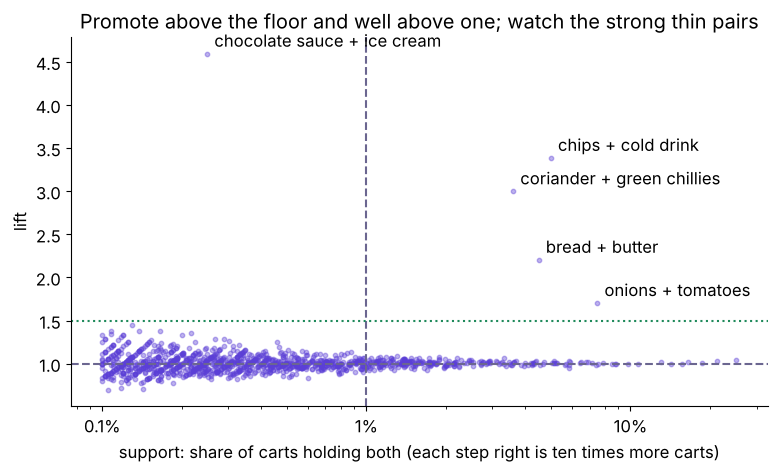

In [3]:
shown = pairs[pairs.support >= 0.001]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(shown.support, shown.lift, s=10, alpha=0.4, color="#5B3FD6")
ax.axvline(floor, color="#6B6690", ls="--"); ax.axhline(1, color="#6B6690", ls="--")
ax.axhline(1.5, color="#1F8A5B", ls=":")
top_thin = pairs[(pairs.support >= 0.002) & (pairs.support < floor)].sort_values("lift").iloc[-1]
for _, r in list(ranked.head(4).iterrows()) + [(None, top_thin)]:
    ax.annotate(f"{r.a} + {r.b}", (r.support, r.lift), xytext=(5, 5), textcoords="offset points")
ax.set_xscale("log"); ax.set_ylabel("lift")
ax.set_xticks([0.001, 0.01, 0.1], ["0.1%", "1%", "10%"])
ax.set_xlabel("support: share of carts holding both (each step right is ten times more carts)")
ax.set_title("Promote above the floor and well above one; watch the strong thin pairs")
plt.show()

## What should the watch list do with a strong pair on few carts?

Ice cream and chocolate sauce read lift 4.60, the strongest pair between
0.2 percent (80 carts, too few even to trial below it)
and the 1 percent floor. The pair is real, 100 carts where chance gives
22, but the strip suggests it only beside ice cream, in
1,600 carts over four weeks, so a rule for it earns little. It goes on a
**watch list**: in two zones a random half of shoppers see it, and it takes the slot on
ice-cream carts only if it beats the next-best suggestion there.

In [4]:
thin = pairs[(pairs.support >= 0.002) & (pairs.support < floor)].sort_values("lift", ascending=False)
print(thin.head(4).round(4).to_string(index=False))
check("ice cream and chocolate sauce lead the thin band", tuple(thin.iloc[0][["a", "b"]]) == ("chocolate sauce", "ice cream"))

              a         b  both  support   lift
chocolate sauce ice cream   100   0.0025 4.5956
      batteries  tomatoes    87   0.0022 1.3594
      bath soap  cucumber    80   0.0020 1.3333
        namkeen      poha   116   0.0029 1.2889
PASS ice cream and chocolate sauce lead the thin band


## What is one slot worth in rupees?

**Margin** is what Instamart keeps from a sale after the item's cost: bread sells for
Rs 45 and keeps Rs 6.70. A slot's margin a day is the cart-page
views times its click-through times the share of clicks that become an add, times the
margin on an added item. Views are 60,000 a day (the mean in `strip_log`
since the change), each showing all three slots, so 180,000 impressions
a day across the strip. The promoted pairs are assumed to click at the
6.4 percent every suggestion other than milk drew. The add rate
0.5 is an assumption with a range of 0.4 to
0.6 (`strip_log` reads 0.50), and the margin Rs 9 an
assumption with a range of Rs 7 to Rs 11 (a `cart_items` line
earns Rs 9.0 on average, milk aside). A click is worth
Rs 4.50 at the middle, Rs 2.80 at the low ends
(0.4 x Rs 7) and Rs 6.60 at the high ends (0.6 x Rs 11).

**Predict before you run.** What does moving milk's half of the impressions to pairs that
beat chance recover in a month?

a) about Rs 50,000
b) about Rs 2 lakh
c) about Rs 6 lakh
d) about Rs 50 lakh

a slot a day: Rs 17,280 with a pair that beats chance, Rs 3,240 with milk
gap: Rs 14,040 a day, Rs 4.2 lakh a month per slot
recovered on milk's 1.5 slots' worth: Rs 6.3 lakh a month (Rs 3.9 lakh to Rs 9.3 lakh across the ranges)


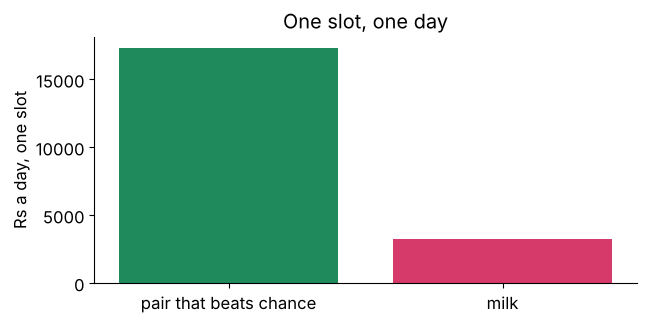

PASS a slot earns Rs 17,280 or Rs 3,240 a day
PASS re-ranking recovers Rs 6.3 lakh a month


In [5]:
views, add_rate, margin = 60_000, 0.5, 9
def slot_day(ctr):
    return views * ctr * add_rate * margin
good, milk = slot_day(0.064), slot_day(0.012)
gap_month = (good - milk) * 30
recovered = gap_month * 3 * 0.5            # three slots, milk on half the impressions
low = views * (0.064 - 0.012) * 0.4 * 7 * 30 * 1.5
high = views * (0.064 - 0.012) * 0.6 * 11 * 30 * 1.5
print(f"a slot a day: Rs {good:,.0f} with a pair that beats chance, Rs {milk:,.0f} with milk")
print(f"gap: Rs {good - milk:,.0f} a day, Rs {gap_month / 1e5:.1f} lakh a month per slot")
print(f"recovered on milk's 1.5 slots' worth: Rs {recovered / 1e5:.1f} lakh a month "
      f"(Rs {low / 1e5:.1f} lakh to Rs {high / 1e5:.1f} lakh across the ranges)")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(["pair that beats chance", "milk"], [good, milk], color=["#1F8A5B", "#D63A6A"])
ax.set_ylabel("Rs a day, one slot"); ax.set_title("One slot, one day")
plt.show()
check("a slot earns Rs 17,280 or Rs 3,240 a day", round(good) == 17_280 and round(milk) == 3_240)
check("re-ranking recovers Rs 6.3 lakh a month", round(recovered / 1e5, 1) == 6.3)

**What happened.** The answer is c: Rs 6.3 lakh a month, between
Rs 3.9 lakh and Rs 9.3 lakh across the two ranges. **The plausible
wrong answer** books sales as the benefit: 1,920 adds a day at about Rs 41.77
each reads as Rs 80,197 a day of "strip revenue", over four times the margin.
**Why it is wrong.** The growth lead counts the margin, never the price; and if the strip
ever adds a bundle discount, that discount is margin handed back to the customer. Swiggy's
shareholder letter for April to June 2025 describes Maxxsaver, a discount unlocked once a
basket passes a set size, in just those terms (checked 12 October 2026).

In [6]:
after = log[log.date >= "2026-09-07"]
other = after[after.suggested_item != "toned milk"]
price = items.drop_duplicates("item").set_index("item").price_rs
price_per_add = (other.groupby("suggested_item").adds.sum() * price).sum() / other.adds.sum()
adds = views * 0.064 * add_rate
print(f"{adds:,.0f} adds a day x Rs {price_per_add:.2f} = Rs {adds * price_per_add:,.0f} of sales; "
      f"the margin is Rs {good:,.0f}")
check("sales overstate the margin more than four times", adds * price_per_add > 4 * good)

1,920 adds a day x Rs 41.77 = Rs 80,197 of sales; the margin is Rs 17,280
PASS sales overstate the margin more than four times


## What can the counts not tell us?

Six doubts, each with the check that settles it. **Together is no proof of cause.** Lift
says chips and cold drink are bought together; it does not show that suggesting cold drink
beside chips makes anyone buy a cold drink they would not have bought. Only a **holdout**
settles that, a share of shoppers kept on the old strip and compared with the rest, the
subject of this week's Monday faculty session on A/B testing (tentative). **Heavy buyers,
each placing many carts:** the top tenth of customers place 38 percent of carts, so lift is
recomputed with every customer counted once, which gives each cart a weight of one over its
customer's number of carts (a shopper with 4 carts counts each as
0.25); the next cell. **The stock-out:** curd ran out in two zones in week
three; the cell after. **Time of day:** morning carts hold milk more often; the same cell.
**Position in the strip:** whatever slot 1 shows draws the most clicks, as chapter 2's split
by slot showed. **The strip feeds its own counts:** an add from the strip puts both items in
one cart, and only the holdout's shoppers, who never see the strip, show the counts without
it.

top tenth of customers: 38% of carts
...and 73% of the carts holding both chips and a cold drink


chips + cold drink: lift 3.39 per cart, 2.56 with each customer counted once
bread + milk: lift 1.04 per cart, 1.04 with each customer counted once


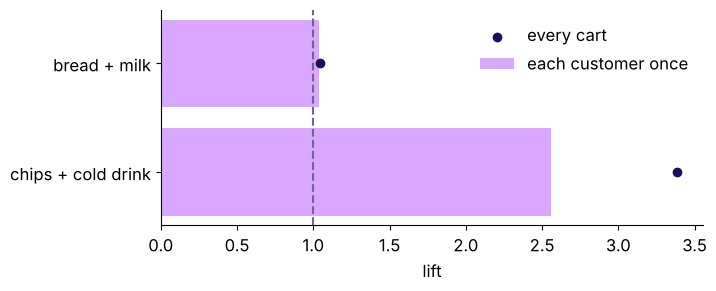

PASS the top tenth place 38 percent of carts
PASS they place 73 percent of the chips and cold drink carts
PASS counted per customer, the party pair shrinks and milk's pair holds


In [7]:
carts["weight"] = 1 / carts.groupby("customer_id").cart_id.transform("count")
w = carts.set_index("cart_id").weight
def lift_per_customer(a, b):
    has_a = baskets.apply(lambda x: a in x); has_b = baskets.apply(lambda x: b in x)
    pa, pb = w[has_a].sum() / w.sum(), w[has_b].sum() / w.sum()
    return w[has_a & has_b].sum() / w.sum() / (pa * pb)
top_tenth = carts.customer_id.value_counts().head(len(carts.customer_id.unique()) // 10)
print(f"top tenth of customers: {top_tenth.sum() / n:.0%} of carts")
both_ids = baskets[baskets.apply(lambda x: "chips" in x and "cold drink" in x)].index
heavy_share = carts.set_index("cart_id").loc[both_ids, "customer_id"].isin(top_tenth.index).mean()
print(f"...and {heavy_share:.0%} of the carts holding both chips and a cold drink")
per_cart = pairs.set_index(["a", "b"]).lift
rows = {"chips + cold drink": (per_cart[("chips", "cold drink")], lift_per_customer("chips", "cold drink")),
        "bread + milk": (per_cart[("bread", "toned milk")], lift_per_customer("bread", "toned milk"))}
for name, (per_cart, per_cust) in rows.items():
    print(f"{name}: lift {per_cart:.2f} per cart, {per_cust:.2f} with each customer counted once")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(list(rows), [r[1] for r in rows.values()], color="#D9A7FF", label="each customer once")
ax.scatter([r[0] for r in rows.values()], list(rows), color="#1A0F5C", zorder=3, label="every cart")
ax.axvline(1, color="#6B6690", ls="--"); ax.legend(frameon=False); ax.set_xlabel("lift")
plt.show()
check("the top tenth place 38 percent of carts", round(top_tenth.sum() / n, 2) == 0.38)
check("they place 73 percent of the chips and cold drink carts", round(heavy_share, 2) == 0.73)
check("counted per customer, the party pair shrinks and milk's pair holds",
      rows["chips + cold drink"][1] < 2.7 and abs(rows["bread + milk"][1] - 1.04) < 0.01)

In [8]:
carts["curd"] = carts.cart_id.isin(items.loc[items.item == "curd", "cart_id"])
carts["week"] = (carts.placed_date.dt.day - 1) // 7 + 1
grid = carts.pivot_table(index="zone", columns="week", values="curd", aggfunc="mean")
print((grid * 100).round().astype(int).to_string())
hit = carts.zone.isin(["Hadapsar", "Viman Nagar"]) & (carts.week == 3)
kept = baskets[carts.loc[~hit, "cart_id"]]
def lift_in(bs, a, b):
    k = len(bs); na = bs.apply(lambda x: a in x).sum(); nb = bs.apply(lambda x: b in x).sum()
    return bs.apply(lambda x: a in x and b in x).sum() * k / (na * nb)
print(f"curd's share: {carts.curd.mean():.1%} of all carts, {carts.loc[~hit, 'curd'].mean():.1%} "
      f"with the two zone-weeks set aside")
print(f"curd and milk lift: {lift_in(baskets, 'curd', 'toned milk'):.2f} and {lift_in(kept, 'curd', 'toned milk'):.2f}")
check("curd is near zero in the two zones in week three", carts.loc[hit, "curd"].mean() < 0.01)
by_band = carts.assign(milk=carts.cart_id.isin(items.loc[items.item == "toned milk", "cart_id"])) \
    .groupby("time_band").milk.mean().sort_values(ascending=False)
print("share of carts holding milk, by time band:", by_band.round(2).to_dict())
for band in by_band.index:
    ids = carts.loc[carts.time_band == band, "cart_id"]
    print(f"  {band}: bread and milk lift {lift_in(baskets[ids], 'bread', 'toned milk'):.2f}")
check("morning carts hold milk most often", by_band.index[0] == "morning")

week            1   2   3   4
zone                         
Aundh          26  29  30  30
Baner          29  27  28  27
Camp           30  27  28  27
Hadapsar       25  27   0  28
Hinjewadi      28  27  28  28
Kalyani Nagar  30  26  26  27
Kothrud        29  27  27  28
Viman Nagar    26  26   1  30
curd's share: 26.0% of all carts, 27.8% with the two zone-weeks set aside


curd and milk lift: 1.01 and 1.01
PASS curd is near zero in the two zones in week three
share of carts holding milk, by time band: {'morning': 0.8, 'afternoon': 0.69, 'evening': 0.68, 'night': 0.66}
  morning: bread and milk lift 1.03
  afternoon: bread and milk lift 1.05


  evening: bread and milk lift 1.05
  night: bread and milk lift 1.03
PASS morning carts hold milk most often


## Does a second route reach the same Rs 6.3 lakh?

Read the milk impressions straight from `strip_log` rather than from "half the slots":
every milk impression moved to a suggestion that beats chance gains the gap in click-through
times the add rate times the margin.

In [9]:
milk_per_day = after[after.suggested_item == "toned milk"].groupby("date").impressions.sum().mean()
route_two = milk_per_day * (0.064 - 0.012) * add_rate * margin * 30
print(f"{milk_per_day:,.0f} milk impressions a day -> Rs {route_two / 1e5:.1f} lakh a month")
check("both routes give Rs 6.3 lakh", round(route_two / 1e5, 1) == round(recovered / 1e5, 1))

90,325 milk impressions a day -> Rs 6.3 lakh a month
PASS both routes give Rs 6.3 lakh


## What does the growth lead take to Friday?

- **Which pairs?** Above a floor of 1 percent of carts: chips and cold drink
  3.39, coriander and green chillies 3.00,
  bread and butter 2.21. Milk takes no slot.
- **The watch list?** Ice cream and chocolate sauce, lift 4.60 on
  100 carts, tested before it is promoted.
- **A slot in rupees?** Rs 17,280 a day with a pair that beats chance,
  Rs 3,240 with milk; moving milk's half of the impressions recovers
  Rs 6.3 lakh a month.
- **What the counts cannot say?** Whether the pair causes the purchase; counted per
  customer, chips and cold drink fall to 2.56 and still beat
  chance; the curd stock-out lowers curd's count and leaves its lift at
  1.01; morning carts hold milk 80 percent of the time
  and bread with milk reads 1.03 to 1.05 in every band.

**In the interview.** "Turn a basket analysis into a recommendation with a number." Name
the pairs above a floor, the incremental adds (the adds that would not have happened
without the strip) times the margin, the cost line (what a promotion gives back, such as a
discount), and the assumption that would change the call.